# BERT 512 token — C3 (berbobot) dan C4 (tanpa bobot), validasi silang 10-fold
**Versi Kaggle (GPU T4 ×2).** Pra-pemrosesan, pembersihan data, label, *fold*, pembagian latih/validasi, dan hiperparameter dibuat **identik** dengan notebook Colab. Satu-satunya yang disesuaikan adalah GPU.

**Ukuran batch.** Colab memakai 1 GPU × batch 16, jadi ukuran batch *efektif* = 16. Di Kaggle dengan 2 GPU (DataParallel), batch efektif dijaga 16 dengan 8 per GPU. Jumlah langkah, penjadwalan *learning rate*, dan dinamika optimasi tetap sama dengan Colab, dan memori per GPU lebih kecil.

In [2]:
# ===== 1. Setup =====
import os
USE_ALL_GPUS = True     # True: pakai kedua T4 (DataParallel). False: hanya 1 GPU.
if not USE_ALL_GPUS:
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # harus sebelum import torch

import re, gc, time, shutil, pickle, glob, hashlib, inspect, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import transformers, datasets
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)

n_gpu = torch.cuda.device_count()
assert n_gpu >= 1, "GPU tidak aktif. Settings -> Accelerator -> GPU T4 x2"
GPU_NAMES = [torch.cuda.get_device_name(i) for i in range(n_gpu)]
for i in range(n_gpu):
    print(f"GPU {i}: {GPU_NAMES[i]} | {torch.cuda.get_device_properties(i).total_memory/1e9:.1f} GB")

torch 2.11.0+cu128 | transformers 5.16.1 | datasets 4.8.5
GPU 0: Tesla T4 | 15.6 GB
GPU 1: Tesla T4 | 15.6 GB


In [3]:
# ===== 2. Konfigurasi (nilai identik dengan notebook Colab) =====
SEED = 42
BERT_NAME = "bert-base-uncased"
EPOCHS = 5
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOP_PATIENCE = 2

BATCH_SIZE = 16          # ukuran batch EFEKTIF (= Colab: 1 GPU x 16)
GRAD_ACCUM = 1           # naikkan jadi 2 hanya kalau kena OOM; batch efektif tetap 16
EVAL_BS_PER_DEVICE = 16  # hanya memengaruhi kecepatan/memori evaluasi, bukan hasil

CONFIGS = {
    "C3": dict(max_length=512, weighted=True),    # 512 token, cross-entropy berbobot kelas
    "C4": dict(max_length=512, weighted=False),   # 512 token, cross-entropy tanpa bobot
}
RUN_CONFIGS = ["C3", "C4"]   # sarankan: jalankan satu per versi (["C3"] lalu ["C4"])
K_LIST = [10]

assert BATCH_SIZE % (n_gpu * GRAD_ACCUM) == 0, "BATCH_SIZE harus habis dibagi (n_gpu x GRAD_ACCUM)"
PER_DEVICE_TRAIN_BS = BATCH_SIZE // (n_gpu * GRAD_ACCUM)
EFFECTIVE_BS = PER_DEVICE_TRAIN_BS * n_gpu * GRAD_ACCUM
print(f"n_gpu={n_gpu} | per-GPU batch={PER_DEVICE_TRAIN_BS} | grad_accum={GRAD_ACCUM} | batch EFEKTIF={EFFECTIVE_BS}")
assert EFFECTIVE_BS == 16, "Batch efektif harus 16 agar sama dengan Colab"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

n_gpu=2 | per-GPU batch=8 | grad_accum=1 | batch EFEKTIF=16


In [4]:
# ===== 3. Data: temukan CSV, audit, pembersihan (kode identik dengan notebook Colab) =====
def find_dataset_csv():
    for p in sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True)):
        try:
            cols = set(pd.read_csv(p, nrows=2).columns)
        except Exception:
            continue
        if {"summary", "genre"} <= cols:
            return p
    raise FileNotFoundError("CSV dengan kolom 'summary' dan 'genre' tidak ditemukan di /kaggle/input. "
                            "Tambahkan dataset Book Genre Prediction lewat Add Data.")

CSV_PATH = find_dataset_csv()
print("CSV:", CSV_PATH)
df_raw = pd.read_csv(CSV_PATH)
print("Bentuk data :", df_raw.shape, "| Kolom:", list(df_raw.columns))

df_raw = df_raw.dropna(subset=['summary', 'genre']).reset_index(drop=True)
n_raw = len(df_raw)
dup_rows   = int(df_raw.duplicated(subset='summary', keep=False).sum())
n_conflict = int(df_raw.groupby('summary')['genre'].nunique().gt(1).sum())

n_labels = df_raw.groupby('summary')['genre'].transform('nunique')
df = df_raw[n_labels == 1].drop_duplicates(subset='summary').reset_index(drop=True)

print(f"Data asli                 : {n_raw}")
print(f"Baris terlibat duplikat   : {dup_rows} ({dup_rows/n_raw*100:.1f}%)")
print(f"Sinopsis berlabel konflik : {n_conflict}")
print(f"Data setelah dibersihkan  : {len(df)}  (dibuang {n_raw-len(df)} baris = {(n_raw-len(df))/n_raw*100:.1f}%)")
assert len(df) == 4446, f"Jumlah data bersih ({len(df)}) beda dari eksperimen Colab (4446): dataset/CSV tidak sama!"

le = LabelEncoder()
df['label'] = le.fit_transform(df['genre'])
label_names = le.classes_
num_labels = len(label_names)
print("Jumlah kelas:", num_labels, dict(enumerate(label_names)))
y_all = df['label'].values

# --- tanda tangan data dan fold: HARUS sama dengan yang dicetak di Colab (lihat sel markdown di bawah) ---
data_sig = hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest()
def make_folds(k):
    return list(StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED).split(df.index.values, df['label'].values))
def fold_signature(folds):
    return hashlib.md5(str([te.tolist() for _, te in folds]).encode()).hexdigest()
print("\nSIGNATURE data :", data_sig)
for k in K_LIST:
    print(f"SIGNATURE fold k={k}:", fold_signature(make_folds(k)))

CSV: /kaggle/input/datasets/dania10/data-csv/data.csv
Bentuk data : (4657, 4) | Kolom: ['index', 'title', 'genre', 'summary']
Data asli                 : 4657
Baris terlibat duplikat   : 228 (4.9%)
Sinopsis berlabel konflik : 96
Data setelah dibersihkan  : 4446  (dibuang 211 baris = 4.5%)
Jumlah kelas: 10 {0: 'crime', 1: 'fantasy', 2: 'history', 3: 'horror', 4: 'psychology', 5: 'romance', 6: 'science', 7: 'sports', 8: 'thriller', 9: 'travel'}

SIGNATURE data : 1ec124d4c29c1aae23dbc8ec8fceccf9
SIGNATURE fold k=10: 1fc2b10bf533dbb1a60f9307a374da92


**Cek kesetaraan dengan Colab (jalankan di notebook Colab, sel manapun setelah `df` terbentuk):**
```python
import hashlib
from sklearn.model_selection import StratifiedKFold
print(hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest())
folds = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=42).split(df.index.values, df['label'].values))
print(hashlib.md5(str([te.tolist() for _, te in folds]).encode()).hexdigest())
```
Dua nilai itu harus **sama persis** dengan `SIGNATURE data` dan `SIGNATURE fold k=10` di Kaggle. Kalau beda, data atau urutan baris tidak sama dan hasilnya tidak boleh dibandingkan.

In [5]:
# ===== 4. Fungsi BERT (identik dengan Colab; hanya penyesuaian multi-GPU pada ukuran batch per GPU) =====
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
device = torch.device("cuda:0")

def to_ds(frame, max_length):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer(b['summary'], truncation=True, padding='max_length', max_length=max_length),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def bert_metrics(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

class WeightedTrainer(Trainer):
    """Cross-entropy berbobot kelas (Persamaan 2). Bobot dipindah ke device logits agar aman di multi-GPU."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.class_weights.to(outputs.logits.device)
        loss = nn.CrossEntropyLoss(weight=w)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def make_args(out_dir):
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=LEARNING_RATE,
              per_device_train_batch_size=PER_DEVICE_TRAIN_BS,
              per_device_eval_batch_size=EVAL_BS_PER_DEVICE,
              gradient_accumulation_steps=GRAD_ACCUM,
              num_train_epochs=EPOCHS, weight_decay=WEIGHT_DECAY,
              load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
              seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params:         kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params:         kw["save_strategy"] = "epoch"
    if "save_total_limit" in params:      kw["save_total_limit"] = 1     # hemat disk, tidak memengaruhi pelatihan
    if "warmup_ratio" in params:          kw["warmup_ratio"] = WARMUP_RATIO
    if "disable_tqdm" in params:          kw["disable_tqdm"] = True      # log lebih ringkas di Kaggle
    return TrainingArguments(**kw)

def run_bert(cfg, train_part, val_part, test_part, tag):
    tr = to_ds(train_part, cfg["max_length"]); va = to_ds(val_part, cfg["max_length"]); te = to_ds(test_part, cfg["max_length"])
    model = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=num_labels).to(device)
    out_dir = f"./bert_{tag}"
    cb = [EarlyStoppingCallback(early_stopping_patience=EARLY_STOP_PATIENCE)]
    if cfg["weighted"]:
        w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
        w = torch.tensor(w, dtype=torch.float)
        trainer = WeightedTrainer(model=model, args=make_args(out_dir), train_dataset=tr, eval_dataset=va,
                                  compute_metrics=bert_metrics, callbacks=cb, class_weights=w)
    else:
        trainer = Trainer(model=model, args=make_args(out_dir), train_dataset=tr, eval_dataset=va,
                          compute_metrics=bert_metrics, callbacks=cb)
    try:
        t0 = time.time(); trainer.train(); elapsed = time.time() - t0
        out = trainer.predict(te)
        epochs_run = float(trainer.state.epoch) if trainer.state.epoch is not None else float("nan")
        best_val_f1 = trainer.state.best_metric
    finally:
        y_true, y_pred = (out.label_ids, np.argmax(out.predictions, axis=-1)) if 'out' in locals() else (None, None)
        del model, trainer
        gc.collect(); torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed,
            "epochs_run": epochs_run, "best_val_f1": best_val_f1}
print("Fungsi BERT siap.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Fungsi BERT siap.


In [6]:
# ===== 5. Uji memori singkat (opsional, ~1 menit): pastikan 512 token x batch efektif 16 muat sebelum run panjang =====
SMOKE_TEST = True
if SMOKE_TEST:
    m = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=num_labels).to(device)
    if n_gpu > 1:
        m = nn.DataParallel(m)
    micro = BATCH_SIZE // GRAD_ACCUM          # batch global per langkah; DataParallel membaginya ke tiap GPU
    x = torch.randint(1000, 5000, (micro, 512)).to(device)
    am = torch.ones_like(x); yb = torch.randint(0, num_labels, (micro,)).to(device)
    for i in range(n_gpu): torch.cuda.reset_peak_memory_stats(i)
    try:
        out = m(input_ids=x, attention_mask=am, labels=yb)
        out.loss.mean().backward()
        for i in range(n_gpu):
            print(f"GPU {i}: puncak memori {torch.cuda.max_memory_allocated(i)/1e9:.1f} GB "
                  f"(+ sekitar 1.8 GB untuk state optimizer AdamW) dari {torch.cuda.get_device_properties(i).total_memory/1e9:.1f} GB")
    except torch.cuda.OutOfMemoryError:
        print("OOM! Set GRAD_ACCUM = 2 di sel konfigurasi (batch efektif tetap 16), lalu jalankan ulang dari sel 2.")
    del m, x, am, yb; gc.collect(); torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU 0: puncak memori 3.0 GB (+ sekitar 1.8 GB untuk state optimizer AdamW) dari 15.6 GB
GPU 1: puncak memori 2.9 GB (+ sekitar 1.8 GB untuk state optimizer AdamW) dari 15.6 GB


In [6]:
# ===== 6. Jalankan: validasi silang dengan checkpoint per fold =====
os.makedirs("hasil", exist_ok=True)

def ckpt_path(cfg_name, k): return f"hasil/bert512_{cfg_name}_k{k}_checkpoint.pkl"

def restore_from_input(path):
    """Sesi baru: ambil checkpoint dari output versi sebelumnya yang di-attach sebagai input."""
    if os.path.exists(path): return
    hits = glob.glob(f"/kaggle/input/**/{os.path.basename(path)}", recursive=True)
    if hits:
        shutil.copy(hits[0], path); print("Checkpoint dipulihkan dari", hits[0])

def run_config(cfg_name, k):
    cfg = CONFIGS[cfg_name]
    folds = make_folds(k)
    fsig = fold_signature(folds)
    setting = dict(max_length=cfg["max_length"], weighted=cfg["weighted"], effective_bs=EFFECTIVE_BS,
                   epochs=EPOCHS, lr=LEARNING_RATE, patience=EARLY_STOP_PATIENCE)
    path = ckpt_path(cfg_name, k); restore_from_input(path)

    results = []
    if os.path.exists(path):
        saved = pickle.load(open(path, "rb"))
        if (saved.get("data_sig"), saved.get("fold_sig"), saved.get("setting")) == (data_sig, fsig, setting):
            results = saved["results"]; print(f"[{cfg_name} k={k}] melanjutkan: {len(results)}/{k} fold sudah selesai.")
        else:
            print(f"[{cfg_name} k={k}] checkpoint lama tidak cocok (data/fold/pengaturan beda) -> diabaikan.")
    done = {r["fold"] for r in results}

    for fold, (tr_idx, te_idx) in enumerate(folds, start=1):
        if fold in done: continue
        tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
        tr_part, va_part = train_test_split(tv_part, test_size=0.15, stratify=tv_part['label'], random_state=SEED)
        r = run_bert(cfg, tr_part, va_part, te_part, f"{cfg_name}_k{k}_fold{fold}")
        acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
        f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
        kap = cohen_kappa_score(r["y_true"], r["y_pred"])
        print(f"[{cfg_name} k={k}] Fold {fold}/{k} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} "
              f"| epoch={r['epochs_run']:.0f} | {r['time_sec']/60:.1f} menit")
        results.append({"fold": fold, "idx": te_part.index.values, "y_true": r["y_true"], "y_pred": r["y_pred"],
                        "time_sec": r["time_sec"], "epochs_run": r["epochs_run"], "best_val_f1": r["best_val_f1"],
                        "acc": acc, "f1_macro": f1m, "kappa": kap})
        pickle.dump({"data_sig": data_sig, "fold_sig": fsig, "setting": setting, "results": results}, open(path, "wb"))
        pd.DataFrame([{kk: v for kk, v in x.items() if kk not in ("idx", "y_true", "y_pred")} for x in sorted(results, key=lambda z: z["fold"])]
                     ).to_csv(f"hasil/bert512_{cfg_name}_k{k}_perfold.csv", index=False)

    results = sorted(results, key=lambda r: r["fold"])
    assert len(results) == k, f"baru {len(results)}/{k} fold selesai"
    pf = pd.DataFrame([{kk: v for kk, v in x.items() if kk not in ("idx", "y_true", "y_pred")} for x in results])
    y_true_all = np.concatenate([r["y_true"] for r in results]); y_pred_all = np.concatenate([r["y_pred"] for r in results])
    idx_all = np.concatenate([r["idx"] for r in results])
    assert (y_true_all == y_all[idx_all]).all(), "indeks fold tidak selaras dengan label"
    f1_genre = f1_score(y_true_all, y_pred_all, average=None, labels=range(num_labels))
    pd.DataFrame({"idx": idx_all, "y_true": y_true_all, "y_pred": y_pred_all}).to_csv(f"hasil/bert512_{cfg_name}_k{k}_oof.csv", index=False)
    summ = {"config": cfg_name, "k": k, "max_length": cfg["max_length"], "weighted": cfg["weighted"],
            "acc_mean": pf["acc"].mean(), "acc_std": pf["acc"].std(),            # std sampel (ddof=1), sama dengan tabel utama
            "f1_mean": pf["f1_macro"].mean(), "f1_std": pf["f1_macro"].std(),
            "kappa_mean": pf["kappa"].mean(), "kappa_std": pf["kappa"].std(),
            "waktu_per_fold_detik": pf["time_sec"].mean(), "n_fold": len(pf),
            "n_gpu": n_gpu, "per_gpu_batch": PER_DEVICE_TRAIN_BS, "effective_bs": EFFECTIVE_BS,
            "gpu": " + ".join(GPU_NAMES)}
    for g, v in zip(label_names, f1_genre): summ[f"f1_{g}"] = round(float(v), 3)
    print(f"\n>>> {cfg_name} k={k}: acc={summ['acc_mean']:.2f} ± {summ['acc_std']:.2f}% | "
          f"F1-macro={summ['f1_mean']:.3f} ± {summ['f1_std']:.3f} | kappa={summ['kappa_mean']:.3f} "
          f"| waktu/fold={summ['waktu_per_fold_detik']:.0f} detik\n")
    return summ

all_summ = []
for cfg_name in RUN_CONFIGS:
    for k in K_LIST:
        print("=" * 22, f"{cfg_name} (max_length={CONFIGS[cfg_name]['max_length']}, weighted={CONFIGS[cfg_name]['weighted']}) k={k}", "=" * 22)
        all_summ.append(run_config(cfg_name, k))
        pd.DataFrame(all_summ).to_csv("hasil/bert512_ringkasan.csv", index=False)

====================== C3 (max_length=512, weighted=True) k=10 ======================


Map:   0%|          | 0/3400 [00:00<?, ? examples/s]

Map:   0%|          | 0/601 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.4565', 'grad_norm': '12.13', 'learning_rate': '3.117e-06', 'epoch': '4.225'}
{'loss': '0.3621', 'grad_norm': '24.77', 'learning_rate': '1.239e-06', 'epoch': '4.695'}
{'eval_loss': '1.406', 'eval_accuracy': '0.792', 'eval_f1_macro': '0.7946', 'eval_kappa': '0.7548', 'eval_runtime': '11.22', 'eval_samples_per_second': '53.58', 'eval_steps_per_second': '1.694', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

{'train_runtime': '1033', 'train_samples_per_second': '16.46', 'train_steps_per_second': '1.031', 'train_loss': '1.224', 'epoch': '5'}
[C4 k=10] Fold 10/10 | acc=78.83% f1=0.803 kappa=0.750 | epoch=5 | 17.2 menit

>>> C4 k=10: acc=78.74 ± 1.15% | F1-macro=0.811 ± 0.014 | kappa=0.749 | waktu/fold=1033 detik



In [7]:
# ===== 7. Ringkasan dan paket hasil =====
res = pd.DataFrame(all_summ)
show = ["config", "k", "acc_mean", "acc_std", "f1_mean", "f1_std", "kappa_mean", "kappa_std", "waktu_per_fold_detik", "n_gpu", "per_gpu_batch", "effective_bs"]
print(res[show].round(3).to_string(index=False))
genre_cols = [c for c in res.columns if c.startswith("f1_") and c not in ("f1_mean", "f1_std")]
print("\nF1 per genre (out-of-fold):")
print(res[["config", "k"] + genre_cols].to_string(index=False))
shutil.make_archive("/kaggle/working/hasil_bert512", "zip", "hasil")
print("\nSelesai. Unduh: hasil_bert512.zip (tab Output pada versi notebook).")

config  k  acc_mean  acc_std  f1_mean  f1_std  kappa_mean  kappa_std  waktu_per_fold_detik  n_gpu  per_gpu_batch  effective_bs
    C3 10    78.677    1.336    0.816   0.020       0.749      0.016              1031.392      2              8            16
    C4 10    78.745    1.146    0.811   0.014       0.749      0.014              1032.742      2              8            16

F1 per genre (out-of-fold):
config  k  f1_crime  f1_fantasy  f1_history  f1_horror  f1_psychology  f1_romance  f1_science  f1_sports  f1_thriller  f1_travel
    C3 10     0.736       0.824       0.836      0.694          0.864       0.779       0.798      0.944        0.766      0.921
    C4 10     0.734       0.824       0.830      0.697          0.888       0.759       0.807      0.930        0.770      0.876

Selesai. Unduh: hasil_bert512.zip (tab Output pada versi notebook).


config  k  acc_mean  acc_std  f1_mean  f1_std  kappa_mean  kappa_std  waktu_per_fold_detik  n_gpu  per_gpu_batch  effective_bs
    C3 10     78.79    1.538    0.819   0.024       0.750      0.018              1027.744      2              8            16
    C4 10     78.07    1.684    0.801   0.023       0.741      0.020               986.404      2              8            16

F1 per genre (out-of-fold):
config  k  f1_crime  f1_fantasy  f1_history  f1_horror  f1_psychology  f1_romance  f1_science  f1_sports  f1_thriller  f1_travel
    C3 10     0.744       0.824       0.841      0.689          0.907       0.755       0.804      0.944        0.762      0.928
    C4 10     0.731       0.817       0.821      0.693          0.864       0.738       0.800      0.911        0.765      0.876

Selesai. Unduh: hasil_bert512.zip (tab Output pada versi notebook).

Total: 4446 | Salah: 948 (21.3%)
     aktual diprediksi  jumlah
0  thriller      crime      92
1     crime   thriller      75
2  thriller     horror      68
3   fantasy    science      65
4   fantasy     horror      52
5    horror   thriller      49
6    horror    fantasy      42
7  thriller    science      37
8   science    fantasy      37
9   fantasy    history      32
Romance: 76 data, benar=60, salah ke thriller=6


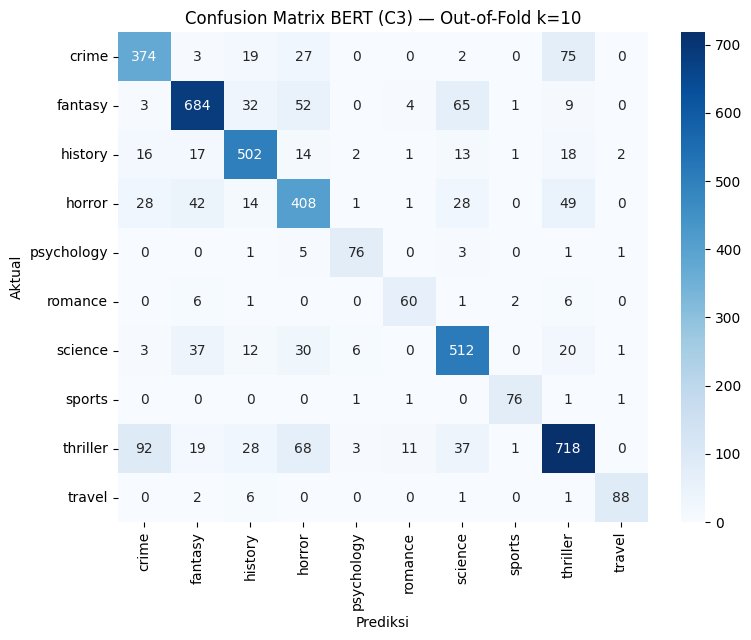

In [8]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

oof = pd.read_csv("hasil/bert512_C3_k10_oof.csv")
label_names = ['crime','fantasy','history','horror','psychology',
               'romance','science','sports','thriller','travel']  # urutan sesuai LabelEncoder

y_true, y_pred = oof['y_true'].values, oof['y_pred'].values
n_total = len(y_true)
n_salah = (y_true != y_pred).sum()
print(f"Total: {n_total} | Salah: {n_salah} ({n_salah/n_total*100:.1f}%)")

# 10 pasangan kesalahan teratas
errors = pd.DataFrame({
    "aktual": [label_names[i] for i in y_true[y_true != y_pred]],
    "diprediksi": [label_names[i] for i in y_pred[y_true != y_pred]],
})
top10 = errors.value_counts().reset_index(name="jumlah").head(10)
print(top10)

# breakdown romance (kelas minoritas, index sesuai label_names)
romance_idx = label_names.index('romance')
mask = y_true == romance_idx
print(f"Romance: {mask.sum()} data, benar={np.sum(y_pred[mask]==romance_idx)}, "
      f"salah ke thriller={np.sum(y_pred[mask]==label_names.index('thriller'))}")

# confusion matrix untuk Gambar 3
cm = confusion_matrix(y_true, y_pred, labels=range(len(label_names)))
plt.figure(figsize=(8,6.5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_names, yticklabels=label_names, cmap='Blues')
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Confusion Matrix BERT (C3) — Out-of-Fold k=10")
plt.tight_layout()
plt.savefig("gambar3_confusion_matrix_c3.png", dpi=200)
plt.show()

In [9]:
n_labels = df_raw.groupby('summary')['genre'].transform('nunique')
baris_konflik = int((n_labels > 1).sum())
kelebihan_salinan = int((n_labels == 1).sum()) - len(df)
print(baris_konflik, kelebihan_salinan, baris_konflik + kelebihan_salinan)   # harus 211

194 17 211


In [10]:
from sklearn.metrics import confusion_matrix
oof = pd.read_csv("hasil/bert512_C3_k10_oof.csv")
cm = confusion_matrix(oof.y_true, oof.y_pred); np.fill_diagonal(cm, 0)
print(sorted(((cm[i,j], label_names[i], label_names[j]) for i in range(10) for j in range(10)), reverse=True)[:10], "| total salah:", cm.sum())

[(np.int64(92), 'thriller', 'crime'), (np.int64(75), 'crime', 'thriller'), (np.int64(68), 'thriller', 'horror'), (np.int64(65), 'fantasy', 'science'), (np.int64(52), 'fantasy', 'horror'), (np.int64(49), 'horror', 'thriller'), (np.int64(42), 'horror', 'fantasy'), (np.int64(37), 'thriller', 'science'), (np.int64(37), 'science', 'fantasy'), (np.int64(32), 'fantasy', 'history')] | total salah: 948
